#### Diagrams of method A (lower bound) and method B (2 pointer)


In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from pathlib import Path

Path("images").mkdir(exist_ok=True)

saved


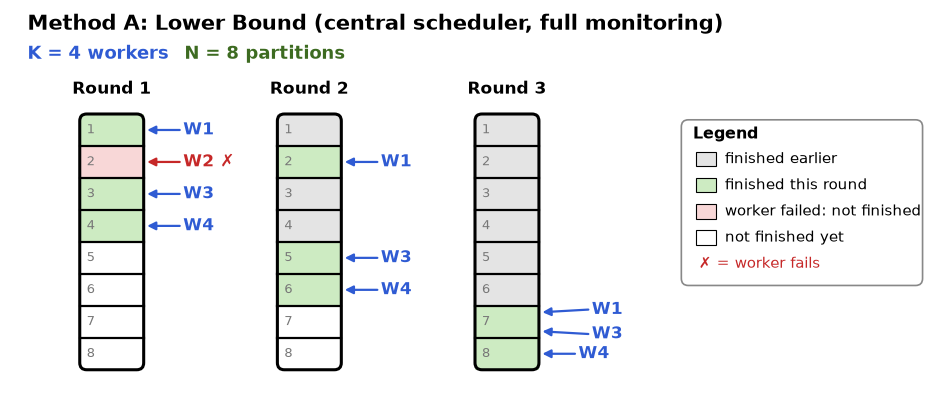

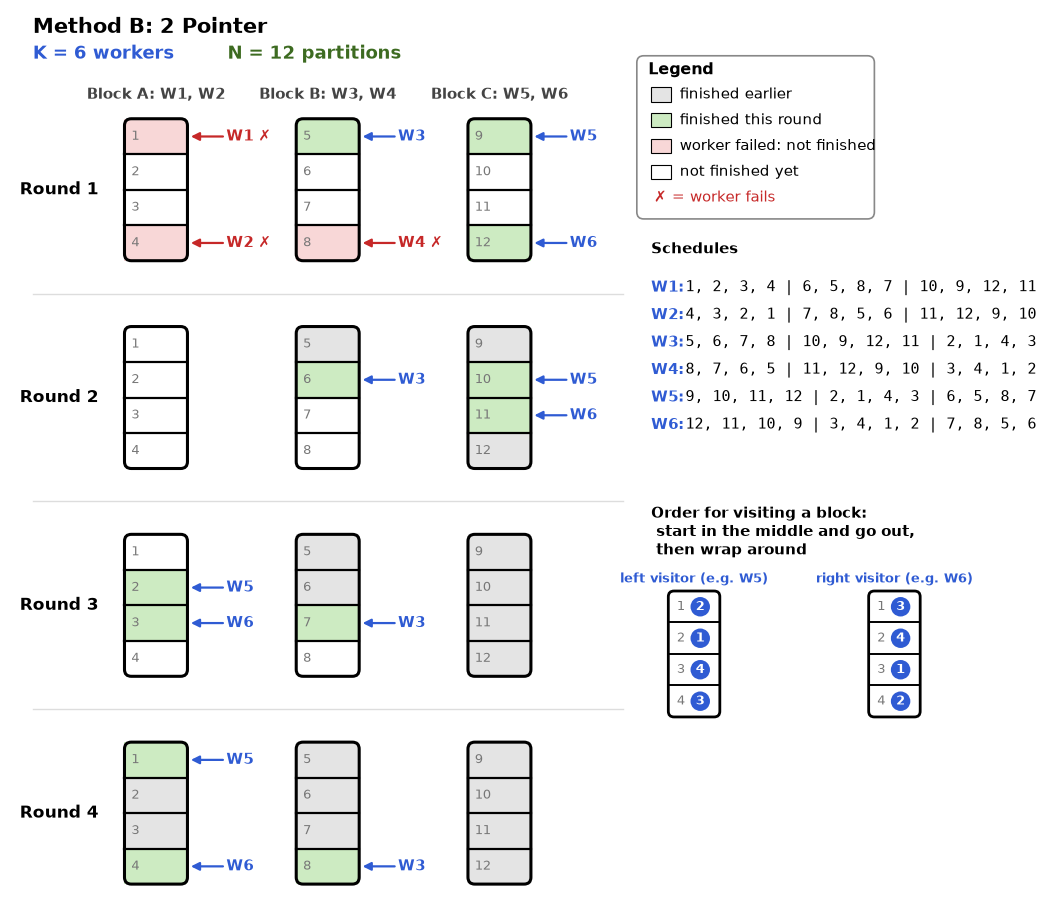

In [23]:
BLUE = "#2F5BD3"          # workers
GREEN = "#3D6B21"         # partitions label
RED = "#C62828"           # failure
DONE = "#CDEBC2"          # finished this round
EARLIER = "#E4E4E4"       # finished in an earlier round
LOST = "#F8D7D7"          # a worker failed on it this round, not finished
CELL_W = 1.1


def draw_stack(ax, x0, y_top, partitions, state, workers, cell_h, label_size=12):
    """One vertical stack of partitions with its top edge at y_top.
    state[p] in {'todo', 'earlier', 'done', 'lost'}; workers = [(label, partition, failed)].
    Each worker gets its own arrow; several workers on one partition are spread vertically."""
    n = len(partitions)
    y_bottom = y_top - n * cell_h
    for i, p in enumerate(partitions):
        y = y_top - (i + 1) * cell_h
        colour = {"done": DONE, "earlier": EARLIER, "lost": LOST}.get(state[p], "white")
        ax.add_patch(Rectangle((x0, y), CELL_W, cell_h, facecolor=colour, edgecolor="none", zorder=1))
        ax.text(x0 + 0.12, y + cell_h / 2, str(p), fontsize=9, color="#777777", va="center", zorder=3)
        if i > 0:
            ax.plot([x0, x0 + CELL_W], [y + cell_h, y + cell_h], color="black", lw=1.6, zorder=2)
    ax.add_patch(FancyBboxPatch((x0, y_bottom), CELL_W, n * cell_h,
                                boxstyle="round,pad=0,rounding_size=0.12",
                                facecolor="none", edgecolor="black", lw=2.2, zorder=4))

    by_partition = {}
    for label, p, failed in workers:
        by_partition.setdefault(p, []).append((label, failed))
    for p, ws in by_partition.items():
        i = partitions.index(p)
        y_mid = y_top - (i + 0.5) * cell_h
        n_w = len(ws)
        tip_step = cell_h * 0.6 / max(n_w - 1, 1)             # arrow tips spread inside the cell
        label_step = 0.42                                      # labels spread far enough to read
        for j, (label, failed) in enumerate(ws):
            k = j - (n_w - 1) / 2
            y_tip = y_mid - k * tip_step if n_w > 1 else y_mid
            y_lab = y_mid - k * label_step if n_w > 1 else y_mid
            colour = RED if failed else BLUE
            x_tail = x0 + CELL_W + (0.85 if n_w > 1 else 0.62)
            ax.annotate("", xy=(x0 + CELL_W + 0.06, y_tip), xytext=(x_tail, y_lab),
                        arrowprops=dict(arrowstyle="-|>", color=colour, lw=1.6, mutation_scale=12,
                                        shrinkA=0, shrinkB=0), zorder=5)
            ax.text(x_tail + 0.06, y_lab, f"{label} ✗" if failed else label, fontsize=label_size,
                    color=colour, va="center", ha="left", fontweight="bold", zorder=5)


def round_states(n, done_before, finished, lost):
    s = {p: "todo" for p in range(1, n + 1)}
    for p in done_before:
        s[p] = "earlier"
    for p in finished:
        s[p] = "done"
    for p in lost:
        s[p] = "lost"
    return s


LEGEND = [(EARLIER, "finished earlier", 2.0), (DONE, "finished this round", 2.35),
          (LOST, "worker failed: not finished", 2.95), ("white", "not finished yet", 2.1)]


def legend(ax, x, y, vertical=False, step=0.45, scale=1.0):
    """Colour key inside a box titled 'Legend'; in a row (method A) or a column (method B).
    (x, y) is the bottom-left corner of the first colour swatch."""
    fontsize = 10.5 if vertical else 9.5
    x_start, y_start = x, y
    for colour, label, width in LEGEND:
        ax.add_patch(Rectangle((x, y), 0.35, 0.25, facecolor=colour, edgecolor="black", lw=0.8, zorder=3))
        ax.text(x + 0.5, y + 0.12, label, va="center", fontsize=fontsize, zorder=3)
        if vertical:
            y -= step
        else:
            x += width * scale
    x_fail = x + 0.05 if vertical else x
    ax.text(x_fail, y + 0.12, "✗ = worker fails", va="center", fontsize=fontsize, color=RED, zorder=3)

    # box around the entries, with the title 'Legend' at the top
    pad = 0.25
    if vertical:
        box_left, box_right = x_start - pad, x_start + 3.9
        box_bottom, box_top = y - pad, y_start + 0.25 + 0.55
        title_y = y_start + 0.25 + 0.3
    else:
        box_left, box_right = x_start - pad, x_fail + 2.0
        box_bottom, box_top = y_start - pad, y_start + 0.25 + 0.6
        title_y = y_start + 0.25 + 0.33
    ax.add_patch(FancyBboxPatch((box_left, box_bottom), box_right - box_left, box_top - box_bottom,
                                boxstyle="round,pad=0,rounding_size=0.12", facecolor="white",
                                edgecolor="#888888", lw=1.2, zorder=1))
    ax.text(box_left + 0.2, title_y, "Legend", fontsize=fontsize + 1, fontweight="bold",
            va="center", ha="left", zorder=3)



# ---------------- Method A: rounds left to right ----------------
def method_A():
    N, cell_h, spacing = 8, 0.55, 3.4
    parts = list(range(1, N + 1))
    rounds = [
        (round_states(N, set(), {1, 3, 4}, {2}),
         [("W1", 1, False), ("W2", 2, True), ("W3", 3, False), ("W4", 4, False)]),
        (round_states(N, {1, 3, 4}, {2, 5, 6}, set()),
         [("W1", 2, False), ("W3", 5, False), ("W4", 6, False)]),
        (round_states(N, {1, 2, 3, 4, 5, 6}, {7, 8}, set()),
         [("W1", 7, False), ("W3", 7, False), ("W4", 8, False)]),          # W1 + W3 share 7 (backup)
    ]
    fig, ax = plt.subplots(figsize=(12, 5.6))
    top = N * cell_h
    for i, (state, workers) in enumerate(rounds):
        x0 = i * spacing
        draw_stack(ax, x0, top, parts, state, workers, cell_h)
        ax.text(x0 + CELL_W / 2, top + 0.35, f"Round {i + 1}", ha="center", fontsize=12, fontweight="bold")
    ax.text(-0.9, top + 1.45, "Method A: Lower Bound (central scheduler, full monitoring)",
            fontsize=15, fontweight="bold")
    ax.text(-0.9, top + 0.95, "K = 4 workers", fontsize=13, color=BLUE, fontweight="bold")
    ax.text(1.8, top + 0.95, "N = 8 partitions", fontsize=13, color=GREEN, fontweight="bold")
    legend(ax, len(rounds) * spacing + 0.4, top - 0.9, vertical=True)   # boxed legend, right of round 3
    ax.set_xlim(-1.2, len(rounds) * spacing + 4.6)
    ax.set_ylim(-0.4, top + 1.8)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.savefig(Path("images") / "f_diagram_method_A.png", dpi = 150)


# ---------------- Method B: blocks side by side, rounds top to bottom ----------------
from matplotlib.patches import FancyArrowPatch

SCHEDULES_12_6 = {   # pair_schedules(12, 6)
    "W1": "1, 2, 3, 4 | 6, 5, 8, 7 | 10, 9, 12, 11",
    "W2": "4, 3, 2, 1 | 7, 8, 5, 6 | 11, 12, 9, 10",
    "W3": "5, 6, 7, 8 | 10, 9, 12, 11 | 2, 1, 4, 3",
    "W4": "8, 7, 6, 5 | 11, 12, 9, 10 | 3, 4, 1, 2",
    "W5": "9, 10, 11, 12 | 2, 1, 4, 3 | 6, 5, 8, 7",
    "W6": "12, 11, 10, 9 | 3, 4, 1, 2 | 7, 8, 5, 6",
}


def wrap_inset(ax, x0, y_top):
    """How a visiting pair moves through a block: start in the middle, go outward, wrap around.
    Two mini blocks, one per visitor; the blue circles give the order the partitions are visited in."""
    from matplotlib.patches import Circle
    cell_h, w = 0.55, 0.9
    ax.text(x0 - 0.3, y_top + 0.55, "Order for visiting a block: \n start in the middle and go out, \n then wrap around",
            fontsize=11, fontweight="bold", va="bottom")
    visitors = [("left visitor (e.g. W5)", [2, 1, 4, 3]), ("right visitor (e.g. W6)", [3, 4, 1, 2])]
    for v, (name, order) in enumerate(visitors):
        xs = x0 + v * 3.5
        ax.text(xs + w / 2, y_top + 0.15, name, ha="center", fontsize=9.5, color=BLUE, fontweight="bold")
        for i, p in enumerate([1, 2, 3, 4]):
            y = y_top - (i + 1) * cell_h
            if i > 0:
                ax.plot([xs, xs + w], [y + cell_h, y + cell_h], color="black", lw=1.4)
            ax.text(xs + 0.15, y + cell_h / 2, str(p), fontsize=9, color="#777777", va="center")
            step = order.index(p) + 1
            ax.add_patch(Circle((xs + w * 0.62, y + cell_h / 2), 0.17, facecolor=BLUE, edgecolor="none"))
            ax.text(xs + w * 0.62, y + cell_h / 2, str(step), color="white", fontsize=9, ha="center",
                    va="center", fontweight="bold")
        ax.add_patch(FancyBboxPatch((xs, y_top - 4 * cell_h), w, 4 * cell_h,
                                    boxstyle="round,pad=0,rounding_size=0.1", facecolor="none",
                                    edgecolor="black", lw=2))
        yc = lambda p: y_top - (p - 0.5) * cell_h
        # solid arrows for moving outward, dashed arc for the wrap-around jump
        first, second, third, fourth = order
        xa = xs + w + 0.12
    #     ax.add_patch(FancyArrowPatch((xa, yc(first)), (xa, yc(second)), connectionstyle="arc3,rad=-0.5",
    #                                  arrowstyle="-|>", mutation_scale=11, color=BLUE, lw=1.5))
    #     ax.add_patch(FancyArrowPatch((xa + 0.05, yc(second)), (xa + 0.05, yc(third)),
    #                                  connectionstyle=f"arc3,rad={-0.45 if third > second else 0.45}",
    #                                  arrowstyle="-|>", mutation_scale=11, color=BLUE, lw=1.5, linestyle="--"))
    #     ax.add_patch(FancyArrowPatch((xa, yc(third)), (xa, yc(fourth)), connectionstyle="arc3,rad=-0.5",
    #                                  arrowstyle="-|>", mutation_scale=11, color=BLUE, lw=1.5))
    # ax.text(x0 - 0.3, y_top - 4 * cell_h - 0.3,
    #         "Left visitor:  2 → 1, wrap to 4 → 3\nRight visitor: 3 → 4, wrap to 1 → 2\n"
    #         "Dashed arrow = wrap around. Done partitions are skipped.",
    #         fontsize=9.5, va="top")


def method_B(rounds, n_workers_note, filename, inset=True):
    cell_h = 0.62
    blocks = [[1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12]]
    block_names = ["Block A: W1, W2", "Block B: W3, W4", "Block C: W5, W6"]
    block_gap, row_gap = 3.0, 1.15
    row_h = 4 * cell_h
    fig, ax = plt.subplots(figsize=(13, 13.5))
    top0 = 0.0
    for b, name in enumerate(block_names):
        ax.text(b * block_gap + CELL_W / 2, top0 + 0.35, name, ha="center", fontsize=11, color="#444444",
                fontweight="bold")
    for r, (state, workers) in enumerate(rounds):
        y_top = top0 - r * (row_h + row_gap)
        ax.text(-0.45, y_top - row_h / 2, f"Round {r + 1}", ha="right", va="center", fontsize=12,
                fontweight="bold")
        for b, parts in enumerate(blocks):
            ws = [w for w in workers if w[1] in parts]
            draw_stack(ax, b * block_gap, y_top, parts, state, ws, cell_h, label_size=11)
        if r < len(rounds) - 1:
            y_sep = y_top - row_h - row_gap / 2
            ax.plot([-1.6, 3 * block_gap - 0.3], [y_sep, y_sep], color="#DDDDDD", lw=1)

    ax.text(-1.6, top0 + 1.5, "Method B: 2 Pointer", fontsize=15,
            fontweight="bold")
    ax.text(-1.6, top0 + 1.05, "K = 6 workers", fontsize=13, color=BLUE, fontweight="bold")
    ax.text(1.8, top0 + 1.05, "N = 12 partitions", fontsize=13, color=GREEN, fontweight="bold")

    sx = 3 * block_gap + 0.2
    # legend at the top right
    legend(ax, sx, top0 + 0.3, vertical=True)
    # schedules below the legend
    y_sched = top0 - 2.35
    ax.text(sx, y_sched, "Schedules", fontsize=11, fontweight="bold")
    for i, (w, s) in enumerate(SCHEDULES_12_6.items()):
        ax.text(sx, y_sched - 0.6 - i * 0.48, f"{w}:", fontsize=11, color=BLUE, fontweight="bold", va="center")
        ax.text(sx + 0.6, y_sched - 0.6 - i * 0.48, s, fontsize=10.5, family="monospace", va="center")
    y_sched_end = y_sched - 0.6 - 5 * 0.48
    if inset:
        wrap_inset(ax, sx + 0.3, y_sched_end - 2.9)

    bottom = top0 - len(rounds) * (row_h + row_gap) + row_gap
    ax.set_xlim(-2.0, sx + 6.4)
    ax.set_ylim(bottom - 0.4, top0 + 1.9)
    ax.set_aspect("equal")
    ax.axis("off")
    plt.savefig(Path("images") / filename, dpi = 150)


# Example 1: block A's own pair (W1, W2) and W4 fail in round 1. W5 and W6 then visit block A,
# entering in the middle (2 and 3) and moving outward (1 and 4).
B_rounds_wrap = [
    (round_states(12, set(), {5, 9, 12}, {1, 4, 8}),
     [("W1", 1, True), ("W2", 4, True), ("W3", 5, False), ("W4", 8, True), ("W5", 9, False), ("W6", 12, False)]),
    (round_states(12, {5, 9, 12}, {6, 10, 11}, set()),
     [("W3", 6, False), ("W5", 10, False), ("W6", 11, False)]),
    (round_states(12, {5, 6, 9, 10, 11, 12}, {2, 3, 7}, set()),
     [("W3", 7, False), ("W5", 2, False), ("W6", 3, False)]),
    (round_states(12, {2, 3, 5, 6, 7, 9, 10, 11, 12}, {1, 4, 8}, set()),
     [("W3", 8, False), ("W5", 1, False), ("W6", 4, False)]),
]

# Example 2: W2 fails in round 1 and W5 in round 2: visiting pairs duplicate each other.
B_rounds_dup = [
    (round_states(12, set(), {1, 5, 8, 9, 12}, {4}),
     [("W1", 1, False), ("W2", 4, True), ("W3", 5, False), ("W4", 8, False), ("W5", 9, False), ("W6", 12, False)]),
    (round_states(12, {1, 5, 8, 9, 12}, {2, 6, 7, 11}, {10}),
     [("W1", 2, False), ("W3", 6, False), ("W4", 7, False), ("W5", 10, True), ("W6", 11, False)]),
    (round_states(12, {1, 2, 5, 6, 7, 8, 9, 11, 12}, {3, 10}, set()),
     [("W1", 3, False), ("W3", 10, False), ("W4", 10, False), ("W6", 10, False)]),
    (round_states(12, {1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12}, {4}, set()),
     [("W1", 4, False), ("W3", 4, False), ("W4", 4, False), ("W6", 4, False)]),
]


method_A()
method_B(B_rounds_wrap, "Example: W1, W2 and W4 fail in round 1;\nW5 and W6 visit block A from the middle.",
         "f_diagram_method_B.png")
# method_B(B_rounds_dup, "Example: W2 fails in round 1, W5 in round 2;\nvisiting pairs duplicate each other.",
        #  "f_diagram_method_B.png", inset=False)
print("saved")